<a href="https://colab.research.google.com/github/azelepou/IntroMachineLearning/blob/main/ML_HW_AnatolyZelepouga_801236217_HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HW6: Fully Connected Neural Networks
Environment: {'python': '3.13.18', 'torch': '2.11.0+cpu', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1'}
Outer 80/20 training/test split. The outer training portion is split 80/20 again into fitting/validation subsets. Select hyperparameters on validation only, then refit all final models on the full outer training portion. Test data is evaluated only after selection. Curves describe the inner selection run.
Dataset: Housing (2).csv
SHA256: a8ef508351b4d6e87b23a831cf316a3d53c794ed9d969c7b697a865a60a3d65f
Split counts: {'total': 545, 'train': 436, 'test': 109, 'fit': 348, 'validation': 88}
Housing inputs: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'semi-furnished', 'unfurnished']
Furnished is the reference category; prices are in millions.

PROBLEM 1a: HOUSING NEURAL NETWORK
Network 1: hidden=[32, 16], lr=0.001, best epoch=129, validation los

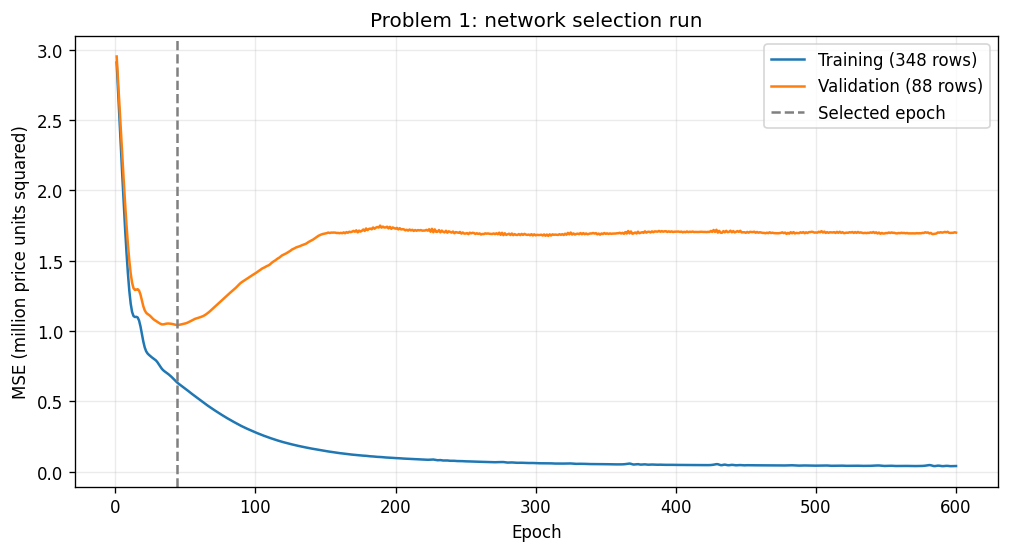


PROBLEM 1b: REGRESSION COMPARISONS
kernel          C  epsilon  validation_mse
linear   1.000000 0.100000        1.159579
linear  10.000000 0.100000        1.159903
linear 100.000000 0.100000        1.159880
   rbf   1.000000 0.100000        1.186915
   rbf  10.000000 0.100000        1.265981
   rbf 100.000000 0.100000        1.575167
Selected SVR: {'kernel': 'linear', 'C': 1.0, 'epsilon': 0.1, 'validation_mse': 1.1595791231308958}
Final test metrics: MSE in millions squared; RMSE in millions.
            model      mse     rmse       r2
   Neural network 1.815631 1.347454 0.640794
Linear regression 1.754319 1.324507 0.652924
              SVR 1.883195 1.372295 0.627427


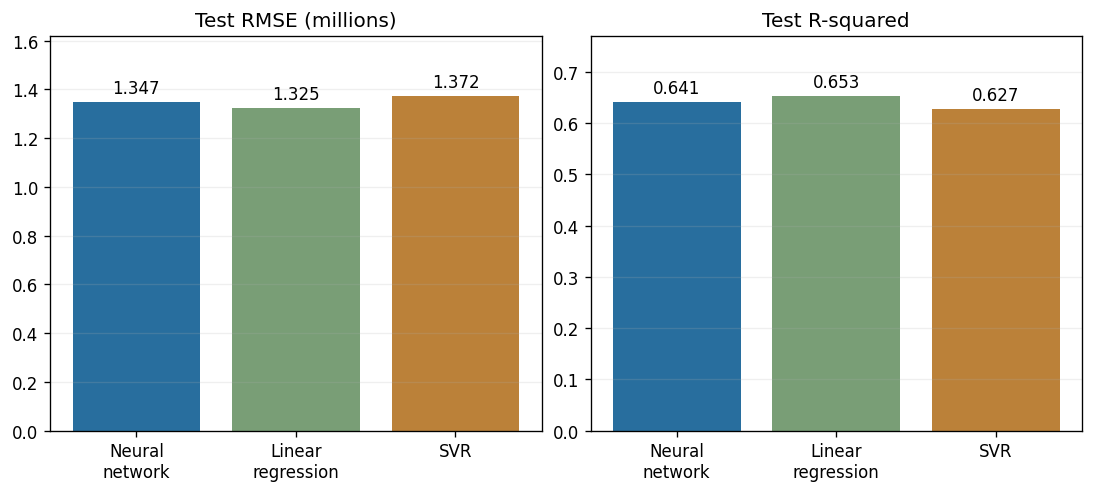

Dataset: Cancer.csv
SHA256: 27f219231dbb30eecbfc1361407ed641ea01be43316e2c707a1baf82c9795e23
Split counts: {'total': 569, 'train': 455, 'test': 114, 'fit': 364, 'validation': 91}
Cancer inputs: 30
Positive class: malignant (1); negative class: benign (0).

PROBLEM 2a: CANCER NEURAL NETWORK
Network 1: hidden=[32, 16], lr=0.001, best epoch=228, validation loss=0.074692
Network 2: hidden=[32, 16], lr=0.003, best epoch=103, validation loss=0.071409
Network 3: hidden=[64, 32], lr=0.001, best epoch=141, validation loss=0.076139
Network 4: hidden=[64, 32], lr=0.003, best epoch=184, validation loss=0.073516
Selected network: {'config': 2, 'hidden': [32, 16], 'lr': 0.003, 'weight_decay': 0.001, 'epoch': 103, 'validation_loss': 0.07140862941741943, 'parameter_count': 1537, 'batch_size': 364}
 config   hidden       lr  weight_decay  epoch  validation_loss  parameter_count  batch_size
      1 [32, 16] 0.001000      0.001000    228         0.074692             1537         364
      2 [32, 16] 0.00

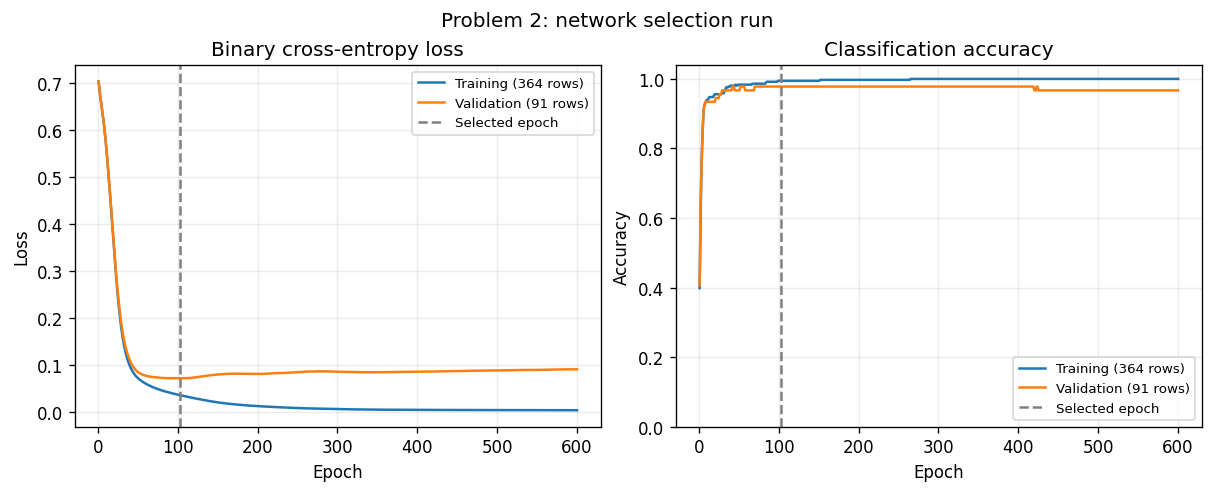


PROBLEM 2b: CLASSIFICATION COMPARISONS
              model  accuracy  precision   recall       f1 kernel         C
Logistic regression  0.978022   1.000000 0.941176 0.969697   none  0.100000
Logistic regression  0.967033   0.942857 0.970588 0.956522   none  1.000000
Logistic regression  0.956044   0.916667 0.970588 0.942857   none 10.000000
                SVM  0.967033   0.969697 0.941176 0.955224 linear  0.100000
                SVM  0.956044   0.916667 0.970588 0.942857 linear  1.000000
                SVM  0.945055   0.891892 0.970588 0.929577 linear 10.000000
                SVM  0.967033   1.000000 0.911765 0.953846    rbf  0.100000
                SVM  0.989011   1.000000 0.970588 0.985075    rbf  1.000000
                SVM  0.978022   0.970588 0.970588 0.970588    rbf 10.000000
Selected classification baselines: {'Logistic regression': {'model': 'Logistic regression', 'accuracy': 0.978021978021978, 'precision': 1.0, 'recall': 0.9411764705882353, 'f1': 0.9696969696969697, 'ke

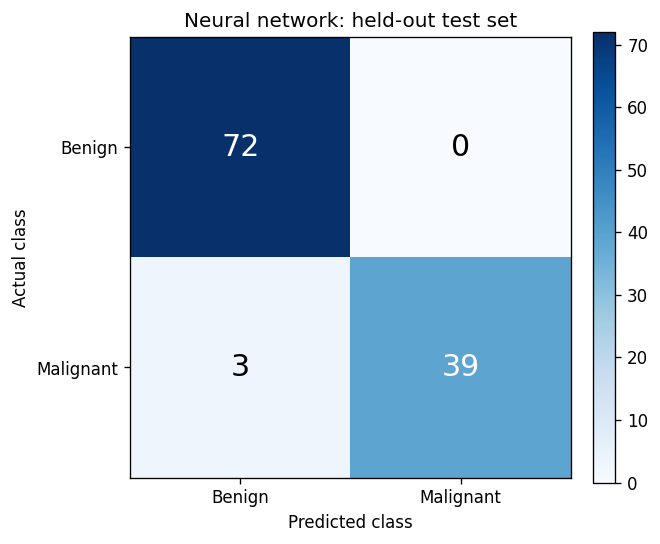

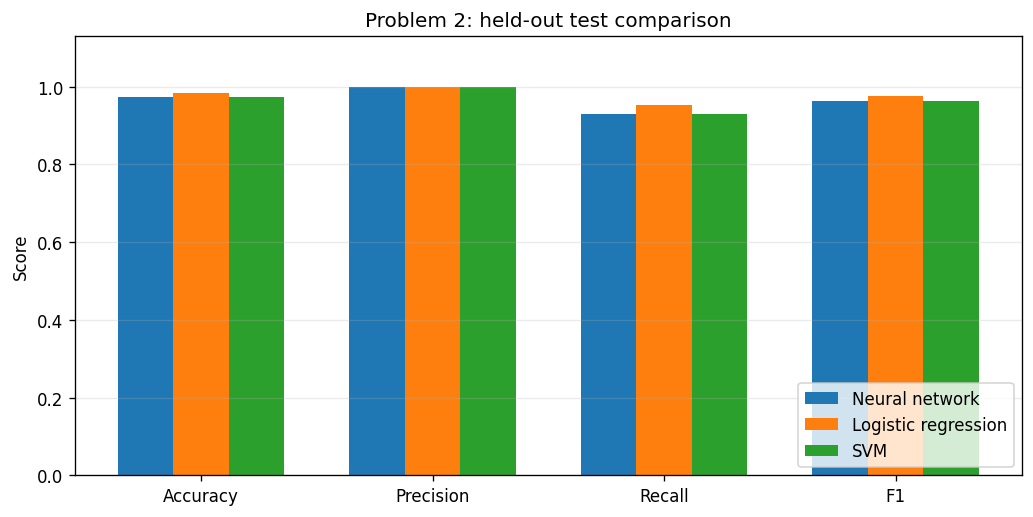


Finished. Results, learning histories, test predictions, splits, and five figures
are saved in: /content/hw6_results
Validation selected the models; the held-out test set was used only for final scoring.


In [8]:
# %% Setup
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix
)

seed = 42
max_epochs = 600
weight_decay = 0.001

configurations = [
    ([32, 16], 0.001),
    ([32, 16], 0.003),
    ([64, 32], 0.001),
    ([64, 32], 0.003)
]

np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.set_default_dtype(torch.float32)

output_dir = Path("hw6_results")
output_dir.mkdir(exist_ok=True)

plt.rcParams.update({"font.size": 10, "figure.dpi": 120})


def read_dataset(filename):
    path = Path(filename)

    if not path.exists():
        matches = sorted(Path(".").glob(path.stem + "*.csv"))

        if len(matches) != 1:
            raise FileNotFoundError(
                "Upload " + filename + " beside this notebook."
            )

        path = matches[0]

    print("Dataset:", path.name)
    print("SHA256:", hashlib.sha256(path.read_bytes()).hexdigest())

    return pd.read_csv(path)


def make_split(X, y, classification=False):
    indices = np.arange(len(y))

    train, test = train_test_split(
        indices,
        test_size=0.20,
        random_state=seed,
        stratify=y if classification else None
    )

    fit, validation = train_test_split(
        train,
        test_size=0.20,
        random_state=seed,
        stratify=y[train] if classification else None
    )

    assert not set(train) & set(test)
    assert not set(fit) & set(validation)
    assert set(fit) | set(validation) == set(train)

    scaler = StandardScaler().fit(X[fit])

    counts = dict(
        total=len(y),
        train=len(train),
        test=len(test),
        fit=len(fit),
        validation=len(validation)
    )

    print("Split counts:", counts)

    return train, test, fit, validation, scaler, counts


def build_network(input_count, hidden):
    torch.manual_seed(seed)

    return nn.Sequential(
        nn.Linear(input_count, hidden[0]),
        nn.ReLU(),
        nn.Linear(hidden[0], hidden[1]),
        nn.ReLU(),
        nn.Linear(hidden[1], 1)
    )


def tensor(values):
    return torch.tensor(values, dtype=torch.float32)


def train_network(
    X, y, hidden, lr, epochs,
    classification=False,
    X_val=None,
    y_val=None,
    loss_scale=1.0
):
    model = build_network(X.shape[1], hidden)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    loss_fn = (
        nn.BCEWithLogitsLoss()
        if classification
        else nn.MSELoss()
    )

    X_tensor = tensor(X)
    y_tensor = tensor(y).reshape(-1, 1)

    if X_val is not None:
        Xv_tensor = tensor(X_val)
        yv_tensor = tensor(y_val).reshape(-1, 1)

    history = []
    best_loss = float("inf")
    best_epoch = epochs

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        loss = loss_fn(model(X_tensor), y_tensor)

        if not torch.isfinite(loss):
            raise ValueError("Non-finite training loss.")

        loss.backward()
        optimizer.step()

        if X_val is not None:
            model.eval()

            with torch.no_grad():
                train_output = model(X_tensor)
                val_output = model(Xv_tensor)

                train_loss = (
                    loss_fn(train_output, y_tensor).item() * loss_scale
                )

                val_loss = (
                    loss_fn(val_output, yv_tensor).item() * loss_scale
                )

                row = {
                    "epoch": epoch,
                    "training_loss": train_loss,
                    "validation_loss": val_loss
                }

                if classification:
                    row["training_accuracy"] = (
                        (train_output >= 0) == (y_tensor == 1)
                    ).float().mean().item()

                    row["validation_accuracy"] = (
                        (val_output >= 0) == (yv_tensor == 1)
                    ).float().mean().item()

            history.append(row)

            if val_loss < best_loss:
                best_loss = val_loss
                best_epoch = epoch

    model.eval()

    return model, pd.DataFrame(history), best_epoch, best_loss


def choose_network(
    X, y, X_val, y_val,
    classification=False,
    loss_scale=1.0
):
    trials = []
    histories = []

    for number, (hidden, lr) in enumerate(configurations, 1):
        model, history, epoch, val_loss = train_network(
            X,
            y,
            hidden,
            lr,
            max_epochs,
            classification,
            X_val,
            y_val,
            loss_scale
        )

        row = dict(
            config=number,
            hidden=hidden,
            lr=lr,
            weight_decay=weight_decay,
            epoch=epoch,
            validation_loss=val_loss,
            parameter_count=sum(
                p.numel() for p in model.parameters()
            ),
            batch_size=len(y)
        )

        trials.append(row)
        histories.append(history)

        print(
            f"Network {number}: hidden={hidden}, lr={lr}, "
            f"best epoch={epoch}, validation loss={val_loss:.6f}"
        )

    best_index = min(
        range(len(trials)),
        key=lambda i: trials[i]["validation_loss"]
    )

    selected = trials[best_index].copy()

    print("Selected network:", selected)

    return selected, trials, histories[best_index]


def predict_network(model, X, classification=False):
    with torch.no_grad():
        values = model(tensor(X)).flatten()

        if classification:
            values = torch.sigmoid(values)

    return values.numpy()


def regression_metrics(name, actual, predicted):
    mse = mean_squared_error(actual, predicted)

    return dict(
        model=name,
        mse=float(mse),
        rmse=float(np.sqrt(mse)),
        r2=float(r2_score(actual, predicted))
    )


def classification_metrics(name, actual, predicted):
    return dict(
        model=name,
        accuracy=float(accuracy_score(actual, predicted)),
        precision=float(
            precision_score(actual, predicted, zero_division=0)
        ),
        recall=float(
            recall_score(actual, predicted, zero_division=0)
        ),
        f1=float(
            f1_score(actual, predicted, zero_division=0)
        )
    )


def save_figure(fig, filename):
    fig.savefig(
        output_dir / filename,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


def show_table(rows, filename):
    table = pd.DataFrame(rows)

    print(
        table.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )

    table.to_csv(output_dir / filename, index=False)


results = {
    "metadata": {
        "name": "Anatoly Zelepouga",
        "student_id": "801236217",
        "github": "https://github.com/azelepou/IntroMachineLearning",
        "seed": seed,
        "max_epochs": max_epochs
    },
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__
    },
    "protocol": (
        "Outer 80/20 training/test split. The outer training portion is "
        "split 80/20 again into fitting/validation subsets. Select "
        "hyperparameters on validation only, then refit all final models "
        "on the full outer training portion. Test data is evaluated only "
        "after selection. Curves describe the inner selection run."
    )
}

print("HW6: Fully Connected Neural Networks")
print("Environment:", results["environment"])
print(results["protocol"])


# %% Problem 1: Housing data
housing = read_dataset("Housing.csv")

binary_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for column in binary_columns:
    housing[column] = housing[column].map({
        "yes": 1.0,
        "no": 0.0
    })

for category in ["semi-furnished", "unfurnished"]:
    housing[category] = (
        housing["furnishingstatus"] == category
    ).astype(float)

housing_features = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "parking",
    "prefarea",
    "semi-furnished",
    "unfurnished"
]

assert housing["furnishingstatus"].isin([
    "furnished",
    "semi-furnished",
    "unfurnished"
]).all()

X_housing = housing[housing_features].to_numpy(dtype=float)
y_housing = housing["price"].to_numpy(dtype=float) / 1_000_000

assert np.isfinite(X_housing).all()
assert np.isfinite(y_housing).all()

h_train, h_test, h_fit, h_val, h_scaler, h_counts = make_split(
    X_housing,
    y_housing
)

Xh_fit = h_scaler.transform(X_housing[h_fit])
Xh_val = h_scaler.transform(X_housing[h_val])

h_mean = y_housing[h_fit].mean()
h_std = y_housing[h_fit].std()

yh_fit = (y_housing[h_fit] - h_mean) / h_std
yh_val = (y_housing[h_val] - h_mean) / h_std

print("Housing inputs:", housing_features)
print("Furnished is the reference category; prices are in millions.")


# %% Problem 1a: Housing neural network
print("\nPROBLEM 1a: HOUSING NEURAL NETWORK")

h_best, h_trials, h_history = choose_network(
    Xh_fit,
    yh_fit,
    Xh_val,
    yh_val,
    loss_scale=h_std ** 2
)

h_history.to_csv(
    output_dir / "housing_learning_history.csv",
    index=False
)

show_table(h_trials, "housing_nn_validation.csv")

fig, ax = plt.subplots(
    figsize=(8.3, 4.5),
    constrained_layout=True
)

ax.plot(
    h_history["epoch"],
    h_history["training_loss"],
    label="Training (348 rows)"
)

ax.plot(
    h_history["epoch"],
    h_history["validation_loss"],
    label="Validation (88 rows)"
)

ax.axvline(
    h_best["epoch"],
    color="gray",
    linestyle="--",
    label="Selected epoch"
)

ax.set(
    title="Problem 1: network selection run",
    xlabel="Epoch",
    ylabel="MSE (million price units squared)"
)

ax.legend()
ax.grid(alpha=0.25)

save_figure(fig, "hw6_problem1_loss.png")


# %% Problem 1b: Regression comparisons
print("\nPROBLEM 1b: REGRESSION COMPARISONS")

h_baseline_trials = []

for kernel in ["linear", "rbf"]:
    for C in [1.0, 10.0, 100.0]:
        candidate = SVR(
            kernel=kernel,
            C=C,
            epsilon=0.1,
            gamma="scale"
        )

        candidate.fit(Xh_fit, yh_fit)

        predicted = candidate.predict(Xh_val) * h_std + h_mean

        h_baseline_trials.append(
            dict(
                kernel=kernel,
                C=C,
                epsilon=0.1,
                validation_mse=float(
                    mean_squared_error(
                        y_housing[h_val],
                        predicted
                    )
                )
            )
        )

h_svr_best = min(
    h_baseline_trials,
    key=lambda row: row["validation_mse"]
)

show_table(
    h_baseline_trials,
    "housing_svr_validation.csv"
)

print("Selected SVR:", h_svr_best)

h_final_scaler = StandardScaler().fit(X_housing[h_train])

Xh_train = h_final_scaler.transform(X_housing[h_train])
Xh_test = h_final_scaler.transform(X_housing[h_test])

h_final_mean = y_housing[h_train].mean()
h_final_std = y_housing[h_train].std()

yh_train = (
    y_housing[h_train] - h_final_mean
) / h_final_std

h_network, _, _, _ = train_network(
    Xh_train,
    yh_train,
    h_best["hidden"],
    h_best["lr"],
    h_best["epoch"]
)

h_best["batch_size"] = len(h_train)

h_linear = LinearRegression().fit(Xh_train, yh_train)

h_svr = SVR(
    kernel=h_svr_best["kernel"],
    C=h_svr_best["C"],
    epsilon=0.1,
    gamma="scale"
).fit(Xh_train, yh_train)

h_predictions = {
    "Neural network": (
        predict_network(h_network, Xh_test)
        * h_final_std + h_final_mean
    ),
    "Linear regression": (
        h_linear.predict(Xh_test)
        * h_final_std + h_final_mean
    ),
    "SVR": (
        h_svr.predict(Xh_test)
        * h_final_std + h_final_mean
    )
}

h_metrics = [
    regression_metrics(name, y_housing[h_test], pred)
    for name, pred in h_predictions.items()
]

print(
    "Final test metrics: MSE in millions squared; "
    "RMSE in millions."
)

show_table(h_metrics, "housing_test_metrics.csv")

pd.DataFrame({
    "row_index": h_test,
    "actual_millions": y_housing[h_test],
    **h_predictions
}).to_csv(
    output_dir / "housing_test_predictions.csv",
    index=False
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9, 4),
    constrained_layout=True
)

for ax, metric, title in zip(
    axes,
    ["rmse", "r2"],
    ["Test RMSE (millions)", "Test R-squared"]
):
    values = [row[metric] for row in h_metrics]

    bars = ax.bar(
        ["Neural\nnetwork", "Linear\nregression", "SVR"],
        values,
        color=["#286E9E", "#799E76", "#BB8139"]
    )

    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(title)
    ax.margins(y=0.18)
    ax.grid(axis="y", alpha=0.2)

save_figure(fig, "hw6_problem1_comparison.png")

results["housing"] = dict(
    features=housing_features,
    input_count=len(housing_features),
    split_counts=h_counts,
    selected_nn=h_best,
    nn_trials=h_trials,
    baseline_trials=h_baseline_trials,
    selected_baseline=h_svr_best,
    test_metrics=h_metrics,
    plots={
        "loss": "hw6_problem1_loss.png",
        "comparison": "hw6_problem1_comparison.png"
    }
)


# %% Problem 2: Breast cancer data
cancer = read_dataset("Cancer.csv")

y_cancer = cancer["diagnosis"].map({
    "B": 0,
    "M": 1
}).to_numpy(dtype=float)

cancer_inputs = cancer.drop(columns=["id", "diagnosis"])

cancer_inputs = cancer_inputs.loc[
    :,
    ~cancer_inputs.columns.str.startswith("Unnamed:")
]

cancer_features = cancer_inputs.columns.tolist()
X_cancer = cancer_inputs.to_numpy(dtype=float)

assert len(cancer_features) == 30
assert np.isfinite(X_cancer).all()
assert np.isfinite(y_cancer).all()

c_train, c_test, c_fit, c_val, c_scaler, c_counts = make_split(
    X_cancer,
    y_cancer,
    classification=True
)

Xc_fit = c_scaler.transform(X_cancer[c_fit])
Xc_val = c_scaler.transform(X_cancer[c_val])

yc_fit = y_cancer[c_fit]
yc_val = y_cancer[c_val]

print("Cancer inputs:", len(cancer_features))
print("Positive class: malignant (1); negative class: benign (0).")


# %% Problem 2a: Cancer neural network
print("\nPROBLEM 2a: CANCER NEURAL NETWORK")

c_best, c_trials, c_history = choose_network(
    Xc_fit,
    yc_fit,
    Xc_val,
    yc_val,
    classification=True
)

c_history.to_csv(
    output_dir / "cancer_learning_history.csv",
    index=False
)

show_table(c_trials, "cancer_nn_validation.csv")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    constrained_layout=True
)

for ax, train_column, val_column, title in [
    (
        axes[0],
        "training_loss",
        "validation_loss",
        "Binary cross-entropy loss"
    ),
    (
        axes[1],
        "training_accuracy",
        "validation_accuracy",
        "Classification accuracy"
    )
]:
    ax.plot(
        c_history["epoch"],
        c_history[train_column],
        label="Training (364 rows)"
    )

    ax.plot(
        c_history["epoch"],
        c_history[val_column],
        label="Validation (91 rows)"
    )

    ax.axvline(
        c_best["epoch"],
        color="gray",
        linestyle="--",
        label="Selected epoch"
    )

    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel="Loss" if ax is axes[0] else "Accuracy"
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

axes[1].set_ylim(0, 1.04)
fig.suptitle("Problem 2: network selection run")

save_figure(fig, "hw6_problem2_learning.png")


# %% Problem 2b: Classification comparisons
print("\nPROBLEM 2b: CLASSIFICATION COMPARISONS")

c_baseline_trials = []

for family in ["Logistic regression", "SVM"]:
    kernels = (
        ["linear", "rbf"]
        if family == "SVM"
        else ["none"]
    )

    for kernel in kernels:
        for C in [0.1, 1.0, 10.0]:
            candidate = (
                SVC(
                    kernel=kernel,
                    C=C,
                    gamma="scale"
                )
                if family == "SVM"
                else LogisticRegression(
                    C=C,
                    max_iter=10000,
                    random_state=seed
                )
            )

            candidate.fit(Xc_fit, yc_fit)

            row = classification_metrics(
                family,
                yc_val,
                candidate.predict(Xc_val)
            )

            row.update(kernel=kernel, C=C)
            c_baseline_trials.append(row)

show_table(
    c_baseline_trials,
    "cancer_baseline_validation.csv"
)

c_selected = {}

for family in ["Logistic regression", "SVM"]:
    c_selected[family] = max(
        [
            row for row in c_baseline_trials
            if row["model"] == family
        ],
        key=lambda row: (row["f1"], row["accuracy"])
    )

print("Selected classification baselines:", c_selected)

c_final_scaler = StandardScaler().fit(X_cancer[c_train])

Xc_train = c_final_scaler.transform(X_cancer[c_train])
Xc_test = c_final_scaler.transform(X_cancer[c_test])

yc_train = y_cancer[c_train]

c_network, _, _, _ = train_network(
    Xc_train,
    yc_train,
    c_best["hidden"],
    c_best["lr"],
    c_best["epoch"],
    classification=True
)

c_best["batch_size"] = len(c_train)

c_logistic = LogisticRegression(
    C=c_selected["Logistic regression"]["C"],
    max_iter=10000,
    random_state=seed
).fit(Xc_train, yc_train)

c_svm = SVC(
    kernel=c_selected["SVM"]["kernel"],
    C=c_selected["SVM"]["C"],
    gamma="scale"
).fit(Xc_train, yc_train)

c_probabilities = predict_network(
    c_network,
    Xc_test,
    classification=True
)

c_predictions = {
    "Neural network": (
        c_probabilities >= 0.5
    ).astype(int),
    "Logistic regression": c_logistic.predict(Xc_test),
    "SVM": c_svm.predict(Xc_test)
}

c_metrics = [
    classification_metrics(
        name,
        y_cancer[c_test],
        pred
    )
    for name, pred in c_predictions.items()
]

print(
    "Final test classification metrics: "
    "malignant is the positive class."
)

show_table(c_metrics, "cancer_test_metrics.csv")

pd.DataFrame({
    "row_index": c_test,
    "actual": y_cancer[c_test],
    "nn_malignant_probability": c_probabilities,
    **c_predictions
}).to_csv(
    output_dir / "cancer_test_predictions.csv",
    index=False
)

c_confusion = confusion_matrix(
    y_cancer[c_test],
    c_predictions["Neural network"],
    labels=[0, 1]
)

print(
    "Neural network confusion matrix "
    "(rows actual, columns predicted; benign, malignant):"
)

print(c_confusion)

fig, ax = plt.subplots(
    figsize=(5.4, 4.5),
    constrained_layout=True
)

im = ax.imshow(c_confusion, cmap="Blues", vmin=0)
fig.colorbar(im, ax=ax)

ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Neural network: held-out test set"
)

for row in range(2):
    for column in range(2):
        ax.text(
            column,
            row,
            str(c_confusion[row, column]),
            ha="center",
            va="center",
            fontsize=18,
            color=(
                "white"
                if c_confusion[row, column] > c_confusion.max() / 2
                else "black"
            )
        )

save_figure(fig, "hw6_problem2_confusion.png")

fig, ax = plt.subplots(
    figsize=(8.5, 4.2),
    constrained_layout=True
)

positions = np.arange(4)

for i, row in enumerate(c_metrics):
    values = [
        row[m]
        for m in ["accuracy", "precision", "recall", "f1"]
    ]

    ax.bar(
        positions + (i - 1) * 0.24,
        values,
        width=0.24,
        label=row["model"]
    )

ax.set(
    xticks=positions,
    xticklabels=["Accuracy", "Precision", "Recall", "F1"],
    ylim=(0, 1.13),
    ylabel="Score",
    title="Problem 2: held-out test comparison"
)

ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.25)

save_figure(fig, "hw6_problem2_comparison.png")

results["cancer"] = dict(
    features=cancer_features,
    input_count=len(cancer_features),
    split_counts=c_counts,
    selected_nn=c_best,
    nn_trials=c_trials,
    baseline_trials=c_baseline_trials,
    selected_baseline=c_selected,
    test_metrics=c_metrics,
    confusion_matrix=c_confusion.tolist(),
    plots={
        "learning": "hw6_problem2_learning.png",
        "confusion": "hw6_problem2_confusion.png",
        "comparison": "hw6_problem2_comparison.png"
    }
)


# %% Results
split_indices = {}

for name, train, test, fit, val in [
    ("housing", h_train, h_test, h_fit, h_val),
    ("cancer", c_train, c_test, c_fit, c_val)
]:
    split_indices[name] = {
        "train": train.tolist(),
        "test": test.tolist(),
        "fit": fit.tolist(),
        "validation": val.tolist()
    }

(output_dir / "split_indices.json").write_text(
    json.dumps(split_indices, indent=2)
)

(output_dir / "results.json").write_text(
    json.dumps(results, indent=2)
)

print(
    "\nFinished. Results, learning histories, test predictions, "
    "splits, and five figures"
)

print("are saved in:", output_dir.resolve())

print(
    "Validation selected the models; "
    "the held-out test set was used only for final scoring."
)